<a href="https://colab.research.google.com/github/hwant2/aerospace-automated-cell-oee-analytics/blob/main/Python/Aerospace_Manufacturing_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:

dataset_url = "https://huggingface.co/datasets/xpertsystems/mfg005-sample/resolve/main/mfg005_synthetic_line_performance.csv"

df = pd.read_csv(dataset_url)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (3000, 118)


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.0,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.0,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.0,7.31,300,19740.0,3955.31,74.9,84.8579


In [3]:
df.head()

,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.0,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.0,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.0,7.31,300,19740.0,3955.31,74.9,84.8579


In [4]:
df.shape

(3000, 118)

In [5]:
df.columns

Index(['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date',
       'shift_number', 'shift_duration_minutes', 'product_id',
       'product_family', 'production_order_id',
       ...
       'direct_labour_cost_usd', 'overhead_cost_usd',
       'material_cost_per_unit_usd', 'scrap_cost_usd', 'rework_cost_usd',
       'downtime_cost_per_minute_usd', 'total_downtime_cost_usd',
       'cost_of_poor_quality_usd', 'value_added_ratio_pct',
       'production_cost_per_unit_usd'],
      dtype='object', length=118)

In [6]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Columns: 118 entries, line_id to production_cost_per_unit_usd
dtypes: float64(70), int64(16), object(32)
memory usage: 2.7+ MB


,shift_number,shift_duration_minutes,number_of_stations,takt_time_seconds,designed_cycle_time_seconds,actual_cycle_time_avg_seconds,actual_cycle_time_std_seconds,actual_cycle_time_min_seconds,actual_cycle_time_max_seconds,cycle_time_percentile_p50,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,...,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1.768000,450.054800,6.560667,107.275967,98.750633,121.787432,13.132230,109.617947,256.71181,121.669113,...,3415.365923,5611.087357,34.790863,2.116313,9.439773,151.760000,9446.704193,1900.896923,50.104167,89.588407
std,0.777417,17.280267,4.192872,100.745838,91.240450,114.248840,19.165534,103.077376,255.65740,114.203637,...,2357.555362,4362.636532,26.614959,12.291030,7.638986,58.803529,8654.189258,1729.719720,14.290641,92.494692
min,1.000000,420.000000,1.000000,6.400000,6.600000,6.844000,0.391000,5.850000,9.71000,6.730000,...,130.360000,121.280000,1.320000,0.000000,0.520000,80.000000,0.000000,0.660000,25.000000,3.071600
25%,1.000000,435.500000,3.000000,34.200000,34.400000,39.410500,2.608250,35.435000,72.98500,39.130000,...,1499.720000,2231.912500,14.407500,0.000000,4.180000,100.000000,3500.000000,714.545000,37.900000,29.785925
50%,2.000000,449.950000,5.000000,59.900000,50.800000,63.714000,5.365500,57.445000,135.61500,63.280000,...,3018.430000,4646.905000,28.550000,0.000000,7.530000,150.000000,7200.000000,1452.280000,50.000000,58.939800
75%,2.000000,464.900000,10.000000,177.700000,170.100000,200.775500,13.258000,180.870000,396.70000,201.640000,...,4988.172500,8041.357500,47.400000,0.000000,12.352500,200.000000,12731.250000,2552.450000,62.500000,116.767075
max,3.000000,480.000000,20.000000,354.200000,290.900000,531.803000,144.252000,497.680000,1503.71000,562.890000,...,10840.870000,24633.110000,201.050000,278.910000,92.970000,300.000000,82057.590000,16416.060000,75.000000,1102.133900


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Columns: 118 entries, line_id to production_cost_per_unit_usd
dtypes: float64(70), int64(16), object(32)
memory usage: 2.7+ MB


In [8]:
df.describe()


,shift_number,shift_duration_minutes,number_of_stations,takt_time_seconds,designed_cycle_time_seconds,actual_cycle_time_avg_seconds,actual_cycle_time_std_seconds,actual_cycle_time_min_seconds,actual_cycle_time_max_seconds,cycle_time_percentile_p50,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,...,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1.768000,450.054800,6.560667,107.275967,98.750633,121.787432,13.132230,109.617947,256.71181,121.669113,...,3415.365923,5611.087357,34.790863,2.116313,9.439773,151.760000,9446.704193,1900.896923,50.104167,89.588407
std,0.777417,17.280267,4.192872,100.745838,91.240450,114.248840,19.165534,103.077376,255.65740,114.203637,...,2357.555362,4362.636532,26.614959,12.291030,7.638986,58.803529,8654.189258,1729.719720,14.290641,92.494692
min,1.000000,420.000000,1.000000,6.400000,6.600000,6.844000,0.391000,5.850000,9.71000,6.730000,...,130.360000,121.280000,1.320000,0.000000,0.520000,80.000000,0.000000,0.660000,25.000000,3.071600
25%,1.000000,435.500000,3.000000,34.200000,34.400000,39.410500,2.608250,35.435000,72.98500,39.130000,...,1499.720000,2231.912500,14.407500,0.000000,4.180000,100.000000,3500.000000,714.545000,37.900000,29.785925
50%,2.000000,449.950000,5.000000,59.900000,50.800000,63.714000,5.365500,57.445000,135.61500,63.280000,...,3018.430000,4646.905000,28.550000,0.000000,7.530000,150.000000,7200.000000,1452.280000,50.000000,58.939800
75%,2.000000,464.900000,10.000000,177.700000,170.100000,200.775500,13.258000,180.870000,396.70000,201.640000,...,4988.172500,8041.357500,47.400000,0.000000,12.352500,200.000000,12731.250000,2552.450000,62.500000,116.767075
max,3.000000,480.000000,20.000000,354.200000,290.900000,531.803000,144.252000,497.680000,1503.71000,562.890000,...,10840.870000,24633.110000,201.050000,278.910000,92.970000,300.000000,82057.590000,16416.060000,75.000000,1102.133900


In [9]:
df.isnull().sum()

,0
line_id,0
plant_id,0
work_center_id,0
shift_id,0
shift_date,0
...,...
downtime_cost_per_minute_usd,0
total_downtime_cost_usd,0
cost_of_poor_quality_usd,0
value_added_ratio_pct,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.columns

Index(['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date',
       'shift_number', 'shift_duration_minutes', 'product_id',
       'product_family', 'production_order_id',
       ...
       'direct_labour_cost_usd', 'overhead_cost_usd',
       'material_cost_per_unit_usd', 'scrap_cost_usd', 'rework_cost_usd',
       'downtime_cost_per_minute_usd', 'total_downtime_cost_usd',
       'cost_of_poor_quality_usd', 'value_added_ratio_pct',
       'production_cost_per_unit_usd'],
      dtype='object', length=118)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Columns: 118 entries, line_id to production_cost_per_unit_usd
dtypes: float64(70), int64(16), object(32)
memory usage: 2.7+ MB


In [13]:
for col in df.columns:
    print(col)


line_id
plant_id
work_center_id
shift_id
shift_date
shift_number
shift_duration_minutes
product_id
product_family
production_order_id
line_type
automation_level
number_of_stations
line_configuration
plant_location
industry_sector
takt_time_seconds
designed_cycle_time_seconds
actual_cycle_time_avg_seconds
actual_cycle_time_std_seconds
actual_cycle_time_min_seconds
actual_cycle_time_max_seconds
cycle_time_percentile_p50
cycle_time_percentile_p95
cycle_time_cov
bottleneck_station_id
bottleneck_cycle_time_seconds
bottleneck_utilisation_pct
secondary_bottleneck_station_id
cycle_time_loss_seconds
planned_production_quantity
actual_production_quantity
good_units_produced
defective_units_produced
scrap_units
rework_units
throughput_rate_actual_uph
throughput_rate_design_uph
throughput_rate_ratio
rolled_throughput_yield_pct
total_parts_processed
wip_queue_avg_units
wip_queue_max_units
output_variance_pct
units_per_operator_hour
planned_production_time_minutes
available_time_minutes
oee_availabi

In [14]:
project_df = df.copy()


In [15]:
project_df.shape

(3000, 118)

In [16]:
project_df = df.copy()

In [17]:
project_df.shape

(3000, 118)

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
import sqlite3

conn = sqlite3.connect("aerospace_oee.db")

df.to_sql("production_data", conn, if_exists="replace", index=False)

3000

In [20]:
query = """
SELECT *
FROM production_data
LIMIT 5;
"""

pd.read_sql_query(query,conn)

,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.0,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.0,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.0,7.31,300,19740.0,3955.31,74.9,84.8579


In [21]:
query = """
SELECT
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units
FROM production_data;
"""

pd.read_sql_query(query,conn)

,planned_units,actual_units,good_units
0,2219673,1448365,1444421


In [22]:
pd.read_sql_query(query, conn).to_dict("records")

[{'planned_units': 2219673, 'actual_units': 1448365, 'good_units': 1444421}]

In [23]:
query = """
SELECT
    SUM(planned_production_quantity)
        - SUM(actual_production_quantity) AS production_gap,
    ROUND(
        100.0 * SUM(actual_production_quantity)
        / SUM(planned_production_quantity), 2
    ) AS target_achievement_pct
FROM production_data;
"""

pd.read_sql_query(query, conn)

,production_gap,target_achievement_pct
0,771308,65.25


In [24]:
query = """
SELECT
    SUM(downtime_category_mechanical) AS mechanical,
    SUM(downtime_category_electrical) AS electrical,
    SUM(downtime_category_tooling) AS tooling,
    SUM(downtime_category_material) AS material,
    SUM(downtime_category_operator) AS operator,
    SUM(downtime_category_quality_hold) AS quality_hold
FROM production_data;
"""

pd.read_sql_query(query, conn)

,mechanical,electrical,tooling,material,operator,quality_hold
0,91668.1,35032.7,23179.5,13654.2,6751.3,14965.9


In [25]:
query = """
SELECT
    maintenance_type_last,
    planned_maintenance_flag,
    equipment_failure_flag,
    equipment_condition_score,
    downtime_unplanned_minutes,
    downtime_planned_minutes
FROM production_data
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,maintenance_type_last,planned_maintenance_flag,equipment_failure_flag,equipment_condition_score,downtime_unplanned_minutes,downtime_planned_minutes
0,predictive,no,no,4.8,0.0,0.0
1,corrective,no,yes,5.3,113.5,0.0
2,predictive,no,yes,5.3,131.1,0.0
3,corrective,no,no,7.0,14.6,0.0
4,corrective,no,yes,6.9,65.8,0.0
5,preventive,no,no,5.3,143.9,0.0
6,preventive,no,no,7.2,25.6,0.0
7,corrective,no,no,6.5,48.5,0.0
8,preventive,no,yes,5.7,92.1,0.0
9,preventive,no,yes,6.5,149.3,0.0


In [26]:
query = """
SELECT
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_condition,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    COUNT(*) AS records
FROM production_data;
"""

pd.read_sql_query(query, conn)

,avg_condition,avg_unplanned_downtime,records
0,6.01,63.66,3000


In [27]:
query = """
SELECT
    maintenance_type_last,
    COUNT(*)  AS records,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_condition
FROM production_data
GROUP BY maintenance_type_last
ORDER BY avg_unplanned_downtime DESC;
"""

pd.read_sql_query(query, conn)


,maintenance_type_last,records,avg_unplanned_downtime,avg_condition
0,emergency,299,66.97,5.89
1,preventive,1246,64.54,5.98
2,predictive,415,64.38,6.05
3,corrective,1040,61.37,6.07


In [28]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime
FROM production_data
GROUP BY work_center_id
ORDER BY total_unplanned_downtime DESC
LIMIT 10;
"""

pd.read_sql_query(query,conn)


,work_center_id,records,total_unplanned_downtime,avg_unplanned_downtime
0,WC-039,77,5690.89,73.91
1,WC-034,81,5439.38,67.15
2,WC-005,66,5136.43,77.82
3,WC-041,64,4657.90,72.78
4,WC-045,63,4642.80,73.70
5,WC-011,61,4598.33,75.38
6,WC-046,71,4591.70,64.67
7,WC-037,66,4588.80,69.53
8,WC-044,73,4547.80,62.30
9,WC-025,68,4475.00,65.81


In [29]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    SUM(CASE
        WHEN equipment_failure_flag = 'yes'
        THEN 1 ELSE 0
    END) AS failure_records,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime
FROM production_data
GROUP BY work_center_id
ORDER BY failure_records DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,work_center_id,records,failure_records,total_unplanned_downtime,avg_unplanned_downtime
0,WC-034,81,36,5439.38,67.15
1,WC-039,77,34,5690.89,73.91
2,WC-037,66,33,4588.80,69.53
3,WC-046,71,30,4591.70,64.67
4,WC-044,73,30,4547.80,62.30
5,WC-041,64,30,4657.90,72.78
6,WC-045,63,29,4642.80,73.70
7,WC-042,66,29,3705.60,56.15
8,WC-025,68,29,4475.00,65.81
9,WC-005,66,29,5136.43,77.82


In [30]:
query = """
SELECT
    equipment_failure_flag,
    COUNT(*) AS records,
    ROUND (AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime
FROM production_data
GROUP BY equipment_failure_flag
ORDER BY equipment_failure_flag;
"""

pd.read_sql_query(query, conn)

,equipment_failure_flag,records,avg_unplanned_downtime,total_unplanned_downtime
0,no,1846,37.56,69336.00
1,yes,1154,105.41,121644.66


In [31]:
query = """
SELECT
    bottleneck_station_id,
    COUNT(*) AS records,
    ROUND (AVG(bottleneck_cycle_time_seconds), 2)
        AS avg_bottleneck_cycle_seconds,
    ROUND(AVG(bottleneck_utilisation_pct), 2)
        AS avg_bottleneck_utilisation_pct,
    ROUND(AVG(cycle_time_loss_seconds), 2)
        AS avg_cycle_time_loss_seconds
FROM production_data
GROUP BY bottleneck_station_id
ORDER BY avg_bottleneck_cycle_seconds DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,bottleneck_station_id,records,avg_bottleneck_cycle_seconds,avg_bottleneck_utilisation_pct,avg_cycle_time_loss_seconds
0,WC-015,5,221.74,93.05,195.35
1,WC-013,6,188.56,94.06,165.22
2,WC-002,645,150.29,94.55,110.07
3,WC-004,285,138.23,95.62,97.91
4,WC-001,706,137.89,94.11,95.90
5,WC-005,236,128.80,96.01,86.88
6,WC-003,433,122.17,95.00,82.21
7,WC-008,117,115.43,95.64,79.37
8,WC-007,132,107.82,95.82,69.94
9,WC-014,13,102.92,96.60,86.02


In [32]:
query = """
SELECT
    Round(SUM(downtime_planned_minutes), 2)
        AS planned_downtime_minutes,
    ROUND (SUM(downtime_unplanned_minutes), 2)
        AS unplanned_downtime_minutes,
    ROUND(AVG(downtime_planned_minutes), 2)
        AS avg_planned_downtime,
    ROUND (AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime
FROM production_data;
"""

pd.read_sql_query(query, conn)


,planned_downtime_minutes,unplanned_downtime_minutes,avg_planned_downtime,avg_unplanned_downtime
0,7544.8,190980.66,2.51,63.66


In [33]:
query = """
SELECT
    SUM(downtime_category_mechanical) AS mechanical,
    SUM(downtime_category_electrical) AS electrical,
    SUM(downtime_category_tooling) AS tooling,
    SUM(downtime_category_material) AS material,
    SUM(downtime_category_operator) As operator,
    SUM(downtime_category_quality_hold) AS quality_hold
FROM production_data;
"""

pd.read_sql_query(query,conn)

,mechanical,electrical,tooling,material,operator,quality_hold
0,91668.1,35032.7,23179.5,13654.2,6751.3,14965.9


In [34]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    SUM(CASE WHEN equipment_failure_flag = 'yes'
        THEN 1 ELSE 0 END) AS failures,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS unplanned_downtime,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_condition
FROM production_data
GROUP BY work_center_id
ORDER BY unplanned_downtime DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,work_center_id,records,failures,unplanned_downtime,avg_condition
0,WC-039,77,34,5690.89,6.08
1,WC-034,81,36,5439.38,6.06
2,WC-005,66,29,5136.43,6.07
3,WC-041,64,30,4657.90,5.94
4,WC-045,63,29,4642.80,6.17
5,WC-011,61,25,4598.33,6.00
6,WC-046,71,30,4591.70,6.18
7,WC-037,66,33,4588.80,6.03
8,WC-044,73,30,4547.80,6.02
9,WC-025,68,29,4475.00,6.04


In [35]:
print("DataFrame exists:", "df" in globals())
print("SQL connection exists:", "conn" in globals())

if "df" in globals():
    print("Data shape:", df.shape)
    print("Columns:", df.columns.tolist()[:20])

DataFrame exists: True
SQL connection exists: True
Data shape: (3000, 118)
Columns: ['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date', 'shift_number', 'shift_duration_minutes', 'product_id', 'product_family', 'production_order_id', 'line_type', 'automation_level', 'number_of_stations', 'line_configuration', 'plant_location', 'industry_sector', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds']


In [36]:
print("Checking SQL table...")

print(pd.read_sql_query("""
SELECT COUNT(*) AS total_records
FROM production_data;
""", conn))

print(pd.read_sql_query("""
SELECT COUNT(DISTINCT work_center_id) AS work_centers
FROM production_data;
""", conn))

Checking SQL table...
   total_records
0           3000
   work_centers
0            49


In [37]:
# Search your dataset foor production-related column names
for col in df.columns:
    if any(word in col.lower() for word in
           ["planned", "actual", "good", "produced", "target", "unit"]):
        print(col)

actual_cycle_time_avg_seconds
actual_cycle_time_std_seconds
actual_cycle_time_min_seconds
actual_cycle_time_max_seconds
planned_production_quantity
actual_production_quantity
good_units_produced
defective_units_produced
scrap_units
rework_units
throughput_rate_actual_uph
wip_queue_avg_units
wip_queue_max_units
units_per_operator_hour
planned_production_time_minutes
performance_loss_units
quality_loss_units
downtime_unplanned_minutes
downtime_planned_minutes
planned_maintenance_flag
operator_headcount_planned
operator_headcount_actual
energy_per_good_unit_kwh
material_cost_per_unit_usd
production_cost_per_unit_usd


In [38]:
query = """
SELECT
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units,
    SUM(defective_units_produced) AS defective_units,
    SUM(scrap_units) AS scrap_units
FROM production_data;
"""

production_results = pd.read_sql_query(query, conn)
production_results

,planned_units,actual_units,good_units,defective_units,scrap_units
0,2219673,1448365,1444421,3944,393


In [39]:
planned = production_results.loc[0, "planned_units"]
actual = production_results.loc[0, "actual_units"]
good = production_results.loc[0, "good_units"]
defective = production_results.loc[0, "defective_units"]
scrap = production_results.loc[0, "scrap_units"]

print(f"Planned production: {planned:,.0f}")
print(f"Actual production: {actual:,.0f}")
print(f"Good units produced: {good:,.0f}")
print(f"Defective units: {defective:,.0f}")
print(f"Scrap units: {scrap:,.0f}")

if planned:
    print(f"Target achievement: {actual / planned * 100:.2f}%")

if actual:
    print(f"Good-unit rate: {good / actual * 100:.2f}%")

Planned production: 2,219,673
Actual production: 1,448,365
Good units produced: 1,444,421
Defective units: 3,944
Scrap units: 393
Target achievement: 65.25%
Good-unit rate: 99.73%


In [40]:
production_results.to_csv(
      "production_performance_results.csv",
      index=False
)

print("Production results saved.")

Production results saved.


In [41]:
from google.colab import files

files.download("production_performance_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    SUM(downtime_unplanned_minutes) AS total_unplanned_downtime,
    ROUND(AVG(downtime_unplanned_minutes), 2) AS avg_unplanned_downtime
FROM production_data
GROUP BY work_center_id
ORDER BY total_unplanned_downtime DESC
LIMIT 10;
"""

downtime_results = pd.read_sql_query(query, conn)
downtime_results

,work_center_id,records,total_unplanned_downtime,avg_unplanned_downtime
0,WC-039,77,5690.892670,73.91
1,WC-034,81,5439.377545,67.15
2,WC-005,66,5136.429090,77.82
3,WC-041,64,4657.900000,72.78
4,WC-045,63,4642.800000,73.70
5,WC-011,61,4598.330022,75.38
6,WC-046,71,4591.700000,64.67
7,WC-037,66,4588.800000,69.53
8,WC-044,73,4547.798952,62.30
9,WC-025,68,4475.000000,65.81


In [43]:
for col in df.columns:
  if any(word in col.lower() for word in
         ["failute", "fault", "breakdown", "alarm"]):
      print(col)


six_big_losses_breakdown


In [44]:
for col in df.columns:
    print(col)

line_id
plant_id
work_center_id
shift_id
shift_date
shift_number
shift_duration_minutes
product_id
product_family
production_order_id
line_type
automation_level
number_of_stations
line_configuration
plant_location
industry_sector
takt_time_seconds
designed_cycle_time_seconds
actual_cycle_time_avg_seconds
actual_cycle_time_std_seconds
actual_cycle_time_min_seconds
actual_cycle_time_max_seconds
cycle_time_percentile_p50
cycle_time_percentile_p95
cycle_time_cov
bottleneck_station_id
bottleneck_cycle_time_seconds
bottleneck_utilisation_pct
secondary_bottleneck_station_id
cycle_time_loss_seconds
planned_production_quantity
actual_production_quantity
good_units_produced
defective_units_produced
scrap_units
rework_units
throughput_rate_actual_uph
throughput_rate_design_uph
throughput_rate_ratio
rolled_throughput_yield_pct
total_parts_processed
wip_queue_avg_units
wip_queue_max_units
output_variance_pct
units_per_operator_hour
planned_production_time_minutes
available_time_minutes
oee_availabi

In [45]:
query = """
SELECT
    equipment_failure_flag,
    COUNT(*) AS records,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND (SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_equipment_condition
FROM production_data
GROUP BY equipment_failure_flag
ORDER BY equipment_failure_flag;
"""

failure_results = pd.read_sql_query(query, conn)
failure_results

,equipment_failure_flag,records,avg_unplanned_downtime,total_unplanned_downtime,avg_equipment_condition
0,no,1846,37.56,69336.00,6.13
1,yes,1154,105.41,121644.66,5.82


In [46]:
failure_results.to_csv(
    "equipment_failure_analysis.csv",
    index=False
)

print("Step 7 results saved.")

Step 7 results saved.


In [47]:
from google.colab import files

files.download("equipment_failure_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
query = """
SELECT
    bottleneck_station_id,
    COUNT(*) AS records,
    ROUND(AVG(bottleneck_cycle_time_seconds), 2) AS avg_bottleneck_cycle_seconds,
    ROUND(AVG(bottleneck_utilisation_pct), 2) AS avg_utilisation_pct,
    ROUND(AVG(cycle_time_loss_seconds), 2) AS avg_cycle_time_loss_seconds
FROM production_data
WHERE bottleneck_station_id IS NOT NULL
GROUP BY bottleneck_Station_id
ORDER BY avg_bottleneck_cycle_seconds DESC
LIMIT 10;
"""

bottleneck_results = pd.read_sql_query(query, conn)
display(bottleneck_results)

,bottleneck_station_id,records,avg_bottleneck_cycle_seconds,avg_utilisation_pct,avg_cycle_time_loss_seconds
0,WC-015,5,221.74,93.05,195.35
1,WC-013,6,188.56,94.06,165.22
2,WC-002,645,150.29,94.55,110.07
3,WC-004,285,138.23,95.62,97.91
4,WC-001,706,137.89,94.11,95.90
5,WC-005,236,128.80,96.01,86.88
6,WC-003,433,122.17,95.00,82.21
7,WC-008,117,115.43,95.64,79.37
8,WC-007,132,107.82,95.82,69.94
9,WC-014,13,102.92,96.60,86.02


In [49]:
bottleneck_results.to_csv("bottleneck_station_analysis.csv", index=False)
print("Bottleneck analysis saved successfully")

Bottleneck analysis saved successfully


In [50]:
from google.colab import files
files.download("bottleneck_station_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
query = """
SELECT
    planned_maintenance_flag,
    maintenance_type_last,
    COUNT(*) AS records,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_equipment_condition,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime
FROM production_data
GROUP BY planned_maintenance_flag, maintenance_type_last
ORDER BY avg_unplanned_downtime DESC;
"""

maintenance_results = pd.read_sql_query(query, conn)
display(maintenance_results)


,planned_maintenance_flag,maintenance_type_last,records,avg_equipment_condition,avg_unplanned_downtime,total_unplanned_downtime
0,no,emergency,263,5.86,70.22,18468.93
1,no,preventive,1142,5.94,66.04,75414.77
2,no,predictive,383,6.02,65.25,24990.57
3,no,corrective,962,6.05,62.56,60184.00
4,yes,predictive,32,6.34,53.99,1727.80
5,yes,preventive,104,6.45,48.05,4997.60
6,yes,corrective,78,6.32,46.71,3643.10
7,yes,emergency,36,6.13,43.16,1553.90


In [52]:
maintenance_results.to_csv("maintenance_condition_analysis.csv", index=False)
print("Maintenance analysis saved successfully")

Maintenance analysis saved successfully


In [53]:
from google.colab import files
files.download("maintenance_condition_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units,
    SUM(defective_units_produced) AS defective_units,
    ROUND(AVG(first_pass_yield_pct), 2) AS avg_first_pass_yield_pct,
    ROUND(AVG(defect_rate_ppm), 2) AS avg_defect_rate_ppm
FROM production_data
GROUP BY work_center_id
ORDER BY avg_defect_rate_ppm DESC
LIMIT 10;
"""

quality_results = pd.read_sql_query(query, conn)
display(quality_results)

,work_center_id,records,actual_units,good_units,defective_units,avg_first_pass_yield_pct,avg_defect_rate_ppm
0,WC-036,57,36325,36239,86,99.69,3083.00
1,WC-020,65,30007,29900,107,99.75,2496.43
2,WC-011,61,29533,29446,87,99.78,2230.32
3,WC-022,52,19677,19621,56,99.78,2211.52
4,WC-021,61,27422,27343,79,99.78,2179.38
5,WC-039,77,39762,39641,121,99.79,2083.28
6,WC-004,59,27192,27117,75,99.80,2023.07
7,WC-031,51,26899,26833,66,99.82,1812.59
8,WC-046,71,32782,32672,110,99.82,1792.71
9,WC-018,53,24132,24063,69,99.82,1777.85


In [55]:
quality_results.to_csv("production_quality_analysis.csv", index=False)
print("Quality analysis saved successfully.")

Quality analysis saved successfully.


In [56]:
from google.colab import files
files.download("production_quality_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    ROUND(SUM(total_downtime_cost_usd), 2)
        AS total_downtime_cost_usd,
    ROUND(SUM(cost_of_poor_quality_usd), 2)
        AS total_cost_of_poor_quality_usd,
    ROUND(SUM(scrap_cost_usd), 2)
        AS total_scrap_cost_usd,
    ROUND(SUM(rework_cost_usd), 2)
        AS total_rework_cost_usd
FROM production_data
GROUP BY work_center_id
ORDER BY SUM(total_downtime_cost_usd)
        +SUM(cost_of_poor_quality_usd) DESC
LIMIT 10;
"""

cost_results = pd.read_sql_query(query, conn)
display(cost_results)

,work_center_id,records,total_downtime_cost_usd,total_cost_of_poor_quality_usd,total_scrap_cost_usd,total_rework_cost_usd
0,WC-039,77,802824.16,161571.50,230.47,776.20
1,WC-034,81,743613.85,149608.59,136.27,749.55
2,WC-005,66,730182.02,146670.31,75.77,558.14
3,WC-044,73,709219.64,142652.79,129.49,679.37
4,WC-045,63,707102.00,141947.76,42.58,484.78
5,WC-025,68,704621.00,141624.96,45.60,655.16
6,WC-002,61,680741.00,136819.02,53.21,617.61
7,WC-049,70,679930.00,136566.67,45.74,534.93
8,WC-028,58,668036.29,134393.70,222.31,564.13
9,WC-013,72,665344.00,133957.38,186.80,701.78


In [58]:
cost_results.to_csv("downtime_quality_cost_analysis.csv", index=False)
print("Cost analysis saved successfully.")

Cost analysis saved successfully.


In [59]:
from google.colab import files
files.download("downtime_quality_cost_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
validation_query = """
SELECT
    COUNT(*) AS total_records,
    COUNT(equipment_failure_flag) AS records_with_failure_flag,
    SUM(CASE
        WHEN equipment_failure_flag = 'yes' THEN 1
        ELSE 0
    END) AS failure_yes,
    SUM(CASE
        WHEN equipment_failure_flag = 'no' THEN 1
        ELSE 0
    END) AS failure_no,
    SUM(CASE
        WHEN equipment_failure_flag is NULL THEN 1
        ELSE 0
    END) AS failure_flag_missing
FROM production_data;
"""

validation_results = pd.read_sql_query(validation_query, conn)
display(validation_results)

,total_records,records_with_failure_flag,failure_yes,failure_no,failure_flag_missing
0,3000,3000,1154,1846,0


In [61]:
print("DataFrame rows:", len(df))
print("SQL table rows:", pd.read_sql_query(
    "SELECT COUNT (*) AS rows FROM production_data", conn
).iloc[0,0])

DataFrame rows: 3000
SQL table rows: 3000


In [62]:
import os

for root, dirs, files_list in os.walk("/content"):
    for name in files_list:
        if "mfg005" in name.lower() or "line_performance" in name.lower():
            print(os.path.join(root, name))

/content/mfg005_synthetic_line_performance.csv


In [63]:
import pandas as pd

df = pd.read_csv ("/content/mfg005_synthetic_line_performance.csv")

print("Rows:", len(df))
print("Columns:", len(df.columns))
display(df.head())

Rows: 3000
Columns: 118


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.0,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.0,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.0,7.31,300,19740.0,3955.31,74.9,84.8579


In [64]:
import os

drive_root = "/content/drive/MyDrive"

if os.path.exists(drive_root):
    for root, dirs, files_list in os.walk(drive_root):
      dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
      for name in files_list:
          if "mfg005" in name.lower() or "line_performance" in name.lower():
              print(os.path.join(root, name))
else:
    print("Google Drive is not mounted.")

In [65]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
import os

drive_root = "/content/drive/MyDrive"
matches = []

for root, dirs, files_list in os.walk(drive_root):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    for name in files_list:
        if "mfg005" in name.lower() or "line_performance" in name.lower():
              matches.append(os.path.join(root, name))
if matches:
  for path in matches:
      print(path)
else:
    print("No matching dataset files found in Google Drive.")

No matching dataset files found in Google Drive.


In [67]:

import pandas as pd

source_url = "https://huggingface.co/datasets/xpertsystems/mfg005-sample/resolve/main/mfg005_synthetic_line_performance.csv"

df_full = pd.read_csv(source_url)

print("Rows:", len(df_full))
print("Columns:", len(df_full.columns))


Rows: 3000
Columns: 118


In [68]:
# Rebuild the SQL table from the verified full dataset
df_full.to_sql("production_data", conn, if_exists="replace", index=False)

# Verify the restored table
check = pd.read_sql_query(
      "SELECT COUNT(*) AS total_records FROM production_data",
      conn
)

print("Restored SQL rows:", check.iloc[0, 0])

Restored SQL rows: 3000


In [69]:
query = """
SELECT
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units,
    SUM(defective_units_produced) AS defective_units,
    SUM(scrap_units) AS scrap_units
FROM production_data;
"""

production_results = pd.read_sql_query(query, conn)
production_results

,planned_units,actual_units,good_units,defective_units,scrap_units
0,2219673,1448365,1444421,3944,393


In [70]:
production_results.to_csv("production_performance_results.csv", index=False)

In [71]:
query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    ROUND(SUM(downtime_unplanned_minutes),2) AS total_unplanned_downtime,
    ROUND(AVG(downtime_unplanned_minutes),2) AS avg_unplanned_downtime
FROM production_data
GROUP BY work_center_id
ORDER BY total_unplanned_downtime DESC
LIMIT 10;
"""

downtime_results = pd.read_sql_query(query, conn)
downtime_results

,work_center_id,records,total_unplanned_downtime,avg_unplanned_downtime
0,WC-039,77,5690.89,73.91
1,WC-034,81,5439.38,67.15
2,WC-005,66,5136.43,77.82
3,WC-041,64,4657.90,72.78
4,WC-045,63,4642.80,73.70
5,WC-011,61,4598.33,75.38
6,WC-046,71,4591.70,64.67
7,WC-037,66,4588.80,69.53
8,WC-044,73,4547.80,62.30
9,WC-025,68,4475.00,65.81


In [72]:
downtime_results.to_csv("work_center_downtime_results.csv", index=False)

In [73]:
query = """
SELECT
    equipment_failure_flag,
    COUNT(*) AS records,
    ROUND(AVG(downtime_unplanned_minutes),2) AS avg_unplanned_downtime,
    ROUND(SUM(downtime_unplanned_minutes),2) AS total_unplanned_downtime,
    ROUND(AVG(equipment_condition_score),2) AS avg_equipment_condition
FROM production_data
GROUP BY equipment_failure_flag
ORDER BY equipment_failure_flag;
"""

failure_results = pd.read_sql_query(query, conn)
failure_results

,equipment_failure_flag,records,avg_unplanned_downtime,total_unplanned_downtime,avg_equipment_condition
0,no,1846,37.56,69336.00,6.13
1,yes,1154,105.41,121644.66,5.82


In [74]:
failure_results.to_csv("equipment_failure_analysis.csv", index=False)

In [75]:
query = """
SELECT
    bottleneck_station_id,
    COUNT(*) AS records,
    ROUND(AVG(bottleneck_cycle_time_seconds),2) AS avg_bottleneck_cycle_seconds,
    ROUND(AVG(bottleneck_utilisation_pct),2) AS avg_utilisation_pct,
    ROUND(AVG(cycle_time_loss_seconds),2) AS avg_cycle_time_loss_seconds
FROM production_data
GROUP BY bottleneck_station_id
ORDER BY avg_bottleneck_cycle_seconds DESC
LIMIT 10;
"""

bottleneck_results = pd.read_sql_query(query, conn)

In [76]:
bottleneck_results.to_csv("bottleneck_station_analysis.csv", index=False)

In [77]:
query = """
SELECT
planned_maintenance_flag,
maintenance_type_last,
COUNT(*) AS records,
ROUND(AVG(equipment_condition_score),2) AS avg_equipment_condition,
ROUND(AVG(downtime_unplanned_minutes),2) AS avg_unplanned_downtime
FROM production_data
GROUP BY planned_maintenance_flag, maintenance_type_last
ORDER BY avg_unplanned_downtime DESC;
"""

maintenance_results = pd.read_sql_query(query, conn)

In [78]:
maintenance_results.to_csv("maintenance_condition_analysis.csv", index=False)

In [79]:
query = """
SELECT
work_center_id,
SUM(actual_production_quantity) AS actual_units,
SUM(good_units_produced) AS good_units,
SUM(defective_units_produced) AS defective_units,
ROUND(AVG(first_pass_yield_pct),2) AS avg_first_pass_yield_pct,
ROUND(AVG(defect_rate_ppm),2) AS avg_defect_rate_ppm
FROM production_data
GROUP BY work_center_id
ORDER BY avg_defect_rate_ppm DESC
LIMIT 10;
"""

quality_results = pd.read_sql_query(query, conn)

In [80]:
quality_results.to_csv("production_quality_analysis.csv", index=False)

In [81]:
query = """
SELECT
work_center_id,
ROUND(SUM(total_downtime_cost_usd),2) AS downtime_cost,
ROUND(SUM(cost_of_poor_quality_usd),2) AS poor_quality_cost
FROM production_data
GROUP BY work_center_id
ORDER BY downtime_cost + poor_quality_cost DESC
LIMIT 10;
"""

cost_results = pd.read_sql_query(query, conn)

In [82]:
cost_results.to_csv("downtime_quality_cost_analysis.csv", index=False)

In [83]:

query = """
SELECT
    COUNT(*) AS total_records,
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units,
    SUM(defective_units_produced) AS defective_units,
    SUM(scrap_units) AS scrap_units
FROM production_data;
"""

production_results = pd.read_sql_query(query, conn)
display(production_results)


,total_records,planned_units,actual_units,good_units,defective_units,scrap_units
0,3000,2219673,1448365,1444421,3944,393


In [84]:

planned = production_results.loc[0, "planned_units"]
actual = production_results.loc[0, "actual_units"]
good = production_results.loc[0, "good_units"]
defective = production_results.loc[0, "defective_units"]
scrap = production_results.loc[0, "scrap_units"]

print(f"Production target achievement: {actual / planned * 100:.2f}%")
print(f"Good-unit rate: {good / actual * 100:.2f}%")
print(f"Defective-unit rate: {defective / actual * 100:.2f}%")
print(f"Scrap units: {scrap:,}")

production_results.to_csv("production_performance_results.csv", index=False)
print("Saved production_performance_results.csv")


Production target achievement: 65.25%
Good-unit rate: 99.73%
Defective-unit rate: 0.27%
Scrap units: 393
Saved production_performance_results.csv


In [85]:

query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime
FROM production_data
GROUP BY work_center_id
ORDER BY total_unplanned_downtime DESC
LIMIT 10;
"""

downtime_results = pd.read_sql_query(query, conn)
display(downtime_results)


,work_center_id,records,total_unplanned_downtime,avg_unplanned_downtime
0,WC-039,77,5690.89,73.91
1,WC-034,81,5439.38,67.15
2,WC-005,66,5136.43,77.82
3,WC-041,64,4657.90,72.78
4,WC-045,63,4642.80,73.70
5,WC-011,61,4598.33,75.38
6,WC-046,71,4591.70,64.67
7,WC-037,66,4588.80,69.53
8,WC-044,73,4547.80,62.30
9,WC-025,68,4475.00,65.81


In [86]:

downtime_results.to_csv("work_center_downtime_results.csv", index=False)
print("Saved work_center_downtime_results.csv")


Saved work_center_downtime_results.csv


In [87]:

from google.colab import files
files.download("work_center_downtime_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:

query = """
SELECT
    equipment_failure_flag,
    COUNT(*) AS records,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_equipment_condition
FROM production_data
GROUP BY equipment_failure_flag
ORDER BY equipment_failure_flag;
"""

failure_results = pd.read_sql_query(query, conn)
display(failure_results)


,equipment_failure_flag,records,avg_unplanned_downtime,total_unplanned_downtime,avg_equipment_condition
0,no,1846,37.56,69336.00,6.13
1,yes,1154,105.41,121644.66,5.82


In [89]:
failure_results.to_csv("equipment_failure_analysis.csv", index=False)

from google.colab import files
files.download("equipment_failure_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [90]:

query = """
SELECT
    bottleneck_station_id,
    COUNT(*) AS records,
    ROUND(AVG(bottleneck_cycle_time_seconds), 2)
        AS avg_bottleneck_cycle_seconds,
    ROUND(AVG(bottleneck_utilisation_pct), 2)
        AS avg_utilisation_pct,
    ROUND(AVG(cycle_time_loss_seconds), 2)
        AS avg_cycle_time_loss_seconds
FROM production_data
WHERE bottleneck_station_id IS NOT NULL
GROUP BY bottleneck_station_id
ORDER BY avg_bottleneck_cycle_seconds DESC
LIMIT 10;
"""

bottleneck_results = pd.read_sql_query(query, conn)
display(bottleneck_results)


,bottleneck_station_id,records,avg_bottleneck_cycle_seconds,avg_utilisation_pct,avg_cycle_time_loss_seconds
0,WC-015,5,221.74,93.05,195.35
1,WC-013,6,188.56,94.06,165.22
2,WC-002,645,150.29,94.55,110.07
3,WC-004,285,138.23,95.62,97.91
4,WC-001,706,137.89,94.11,95.90
5,WC-005,236,128.80,96.01,86.88
6,WC-003,433,122.17,95.00,82.21
7,WC-008,117,115.43,95.64,79.37
8,WC-007,132,107.82,95.82,69.94
9,WC-014,13,102.92,96.60,86.02


In [91]:

bottleneck_results.to_csv("bottleneck_station_analysis.csv", index=False)

from google.colab import files
files.download("bottleneck_station_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [92]:

query = """
SELECT
    planned_maintenance_flag,
    maintenance_type_last,
    COUNT(*) AS records,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_equipment_condition,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(SUM(downtime_unplanned_minutes), 2)
        AS total_unplanned_downtime
FROM production_data
GROUP BY planned_maintenance_flag, maintenance_type_last
ORDER BY avg_unplanned_downtime DESC;
"""

maintenance_results = pd.read_sql_query(query, conn)
display(maintenance_results)


,planned_maintenance_flag,maintenance_type_last,records,avg_equipment_condition,avg_unplanned_downtime,total_unplanned_downtime
0,no,emergency,263,5.86,70.22,18468.93
1,no,preventive,1142,5.94,66.04,75414.77
2,no,predictive,383,6.02,65.25,24990.57
3,no,corrective,962,6.05,62.56,60184.00
4,yes,predictive,32,6.34,53.99,1727.80
5,yes,preventive,104,6.45,48.05,4997.60
6,yes,corrective,78,6.32,46.71,3643.10
7,yes,emergency,36,6.13,43.16,1553.90


In [93]:

maintenance_results.to_csv("maintenance_condition_analysis.csv", index=False)

from google.colab import files
files.download("maintenance_condition_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:

query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units,
    SUM(defective_units_produced) AS defective_units,
    ROUND(AVG(first_pass_yield_pct), 2)
        AS avg_first_pass_yield_pct,
    ROUND(AVG(defect_rate_ppm), 2)
        AS avg_defect_rate_ppm
FROM production_data
GROUP BY work_center_id
ORDER BY avg_defect_rate_ppm DESC
LIMIT 10;
"""

quality_results = pd.read_sql_query(query, conn)
display(quality_results)


,work_center_id,records,actual_units,good_units,defective_units,avg_first_pass_yield_pct,avg_defect_rate_ppm
0,WC-036,57,36325,36239,86,99.69,3083.00
1,WC-020,65,30007,29900,107,99.75,2496.43
2,WC-011,61,29533,29446,87,99.78,2230.32
3,WC-022,52,19677,19621,56,99.78,2211.52
4,WC-021,61,27422,27343,79,99.78,2179.38
5,WC-039,77,39762,39641,121,99.79,2083.28
6,WC-004,59,27192,27117,75,99.80,2023.07
7,WC-031,51,26899,26833,66,99.82,1812.59
8,WC-046,71,32782,32672,110,99.82,1792.71
9,WC-018,53,24132,24063,69,99.82,1777.85


In [95]:

quality_results.to_csv("production_quality_analysis.csv", index=False)

from google.colab import files
files.download("production_quality_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [96]:

query = """
SELECT
    work_center_id,
    COUNT(*) AS records,
    ROUND(SUM(total_downtime_cost_usd), 2)
        AS total_downtime_cost_usd,
    ROUND(SUM(cost_of_poor_quality_usd), 2)
        AS total_cost_of_poor_quality_usd,
    ROUND(SUM(scrap_cost_usd), 2)
        AS total_scrap_cost_usd,
    ROUND(SUM(rework_cost_usd), 2)
        AS total_rework_cost_usd
FROM production_data
GROUP BY work_center_id
ORDER BY
    SUM(total_downtime_cost_usd)
    + SUM(cost_of_poor_quality_usd) DESC
LIMIT 10;
"""

cost_results = pd.read_sql_query(query, conn)
display(cost_results)


,work_center_id,records,total_downtime_cost_usd,total_cost_of_poor_quality_usd,total_scrap_cost_usd,total_rework_cost_usd
0,WC-039,77,802824.16,161571.50,230.47,776.20
1,WC-034,81,743613.85,149608.59,136.27,749.55
2,WC-005,66,730182.02,146670.31,75.77,558.14
3,WC-044,73,709219.64,142652.79,129.49,679.37
4,WC-045,63,707102.00,141947.76,42.58,484.78
5,WC-025,68,704621.00,141624.96,45.60,655.16
6,WC-002,61,680741.00,136819.02,53.21,617.61
7,WC-049,70,679930.00,136566.67,45.74,534.93
8,WC-028,58,668036.29,134393.70,222.31,564.13
9,WC-013,72,665344.00,133957.38,186.80,701.78


In [97]:

cost_results.to_csv("downtime_quality_cost_analysis.csv", index=False)

from google.colab import files
files.download("downtime_quality_cost_analysis.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [98]:
from google.colab import files

production_results.to_csv("production_performance_results.csv", index=False)
files.download("production_performance_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [99]:
failure_results.to_csv("equipment_failure_analysis.csv", index=False)
files.download("equipment_failure_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [100]:
downtime_results.to_csv("work_center_downtime_results.csv", index=False)
files.download("work_center_downtime_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [101]:

required_results = {
    "Production Performance": "production_results",
    "Work Center Downtime": "downtime_results",
    "Equipment Failure": "failure_results",
    "Bottleneck Analysis": "bottleneck_results",
    "Maintenance Analysis": "maintenance_results",
    "Production Quality": "quality_results",
    "Downtime and Quality Costs": "cost_results",
}

for label, variable_name in required_results.items():
    result = globals().get(variable_name)

    if result is None:
        print(f"MISSING: {label} — rerun its analysis cell")
    else:
        print(f"READY: {label} — {len(result):,} result rows")

print("\nSource table record count:")
print(conn.execute(
    "SELECT COUNT(*) FROM production_data"
).fetchone()[0])


READY: Production Performance — 1 result rows
READY: Work Center Downtime — 10 result rows
READY: Equipment Failure — 2 result rows
READY: Bottleneck Analysis — 10 result rows
READY: Maintenance Analysis — 8 result rows
READY: Production Quality — 10 result rows
READY: Downtime and Quality Costs — 10 result rows

Source table record count:
3000



# Aerospace Automated Manufacturing Cell
### Executive Operations Dashboard
**Dataset:** Synthetic manufacturing case study | **Records:** 3,000


,KPI,Result
0,Production target achievement,65.25%
1,Good-unit rate,99.73%
2,Defective-unit rate,0.27%
3,Actual production,"1,448,365 units"
4,Equipment-failure records,"1,154"
5,Top downtime work center,WC-039
6,Top-ranked combined cost exposure,"$964,395.66 (WC-039)"


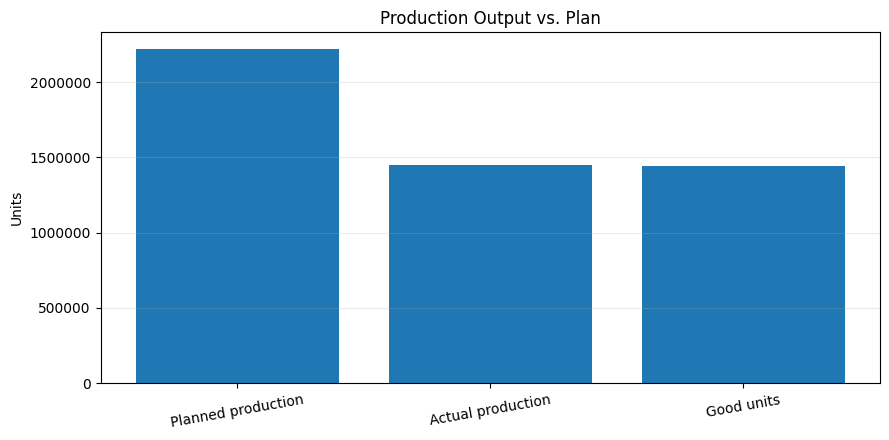

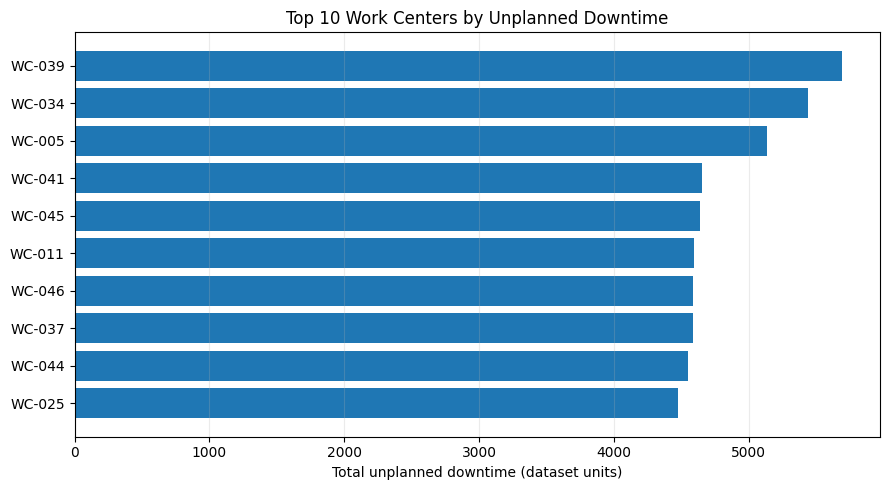

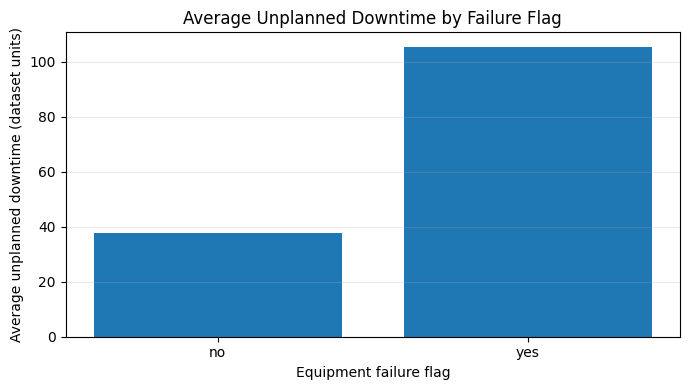


### Initial operational findings

- Production achieved **65.25%** of plan, leaving a gap of **771,308 units**.
- The calculated good-unit rate is **99.73%**; the defective-unit rate is **0.27%**.
- **WC-039** ranks highest among the displayed work centers for unplanned downtime.
- **WC-039** ranks highest in the provided cost-results table by combined downtime and poor-quality cost exposure (**$964,395.66**).

**Interpretation note:** These figures come from synthetic data. The cost ranking is limited to the rows returned by the existing analysis, and the relationships shown are descriptive—not proof of cause and effect.


In [102]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Pull verified headline metrics from the analysis results
p = production_results.iloc[0]
f = failure_results.copy()
d = downtime_results.copy()
c = cost_results.copy()

planned = int(p["planned_units"])
actual = int(p["actual_units"])
good = int(p["good_units"])
defective = int(p["defective_units"])
scrap = int(p["scrap_units"])

achievement = actual / planned * 100 if planned else 0
good_rate = good / actual * 100 if actual else 0
defect_rate = defective / actual * 100 if actual else 0

failure_row = f[
    f.iloc[:, 0].astype(str).str.lower().eq("yes")
]

if not failure_row.empty:
    failure_count = int(failure_row.iloc[0]["records"])
    failure_downtime = float(
        failure_row.iloc[0]["avg_unplanned_downtime"]
    )
else:
    failure_count = None
    failure_downtime = None

top_downtime = d.sort_values(
    "total_unplanned_downtime", ascending=False
).iloc[0]

# Cost exposure: use the first row of the already-ranked cost results
top_cost = c.iloc[0]
cost_center = top_cost["work_center_id"]
combined_cost = (
    float(top_cost["total_downtime_cost_usd"])
    + float(top_cost["total_cost_of_poor_quality_usd"])
)

display(Markdown("""
# Aerospace Automated Manufacturing Cell
### Executive Operations Dashboard
**Dataset:** Synthetic manufacturing case study | **Records:** 3,000
"""))

kpis = pd.DataFrame({
    "KPI": [
        "Production target achievement",
        "Good-unit rate",
        "Defective-unit rate",
        "Actual production",
        "Equipment-failure records",
        "Top downtime work center",
        "Top-ranked combined cost exposure"
    ],
    "Result": [
        f"{achievement:.2f}%",
        f"{good_rate:.2f}%",
        f"{defect_rate:.2f}%",
        f"{actual:,} units",
        f"{failure_count:,}" if failure_count is not None else "N/A",
        str(top_downtime["work_center_id"]),
        f"${combined_cost:,.2f} ({cost_center})"
    ]
})

display(kpis)

# Production target vs. actual
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(
    ["Planned production", "Actual production", "Good units"],
    [planned, actual, good]
)
ax.set_title("Production Output vs. Plan")
ax.set_ylabel("Units")
ax.ticklabel_format(axis="y", style="plain")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Work centers with the highest unplanned downtime
downtime_col = "total_unplanned_downtime"
downtime_plot = d.sort_values(
    downtime_col, ascending=True
).tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    downtime_plot["work_center_id"].astype(str),
    downtime_plot[downtime_col]
)
ax.set_title("Top 10 Work Centers by Unplanned Downtime")
ax.set_xlabel("Total unplanned downtime (dataset units)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# Failure vs. non-failure comparison
failure_label_col = f.columns[0]
avg_downtime_col = "avg_unplanned_downtime"

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    f[failure_label_col].astype(str),
    f[avg_downtime_col]
)
ax.set_title("Average Unplanned Downtime by Failure Flag")
ax.set_xlabel("Equipment failure flag")
ax.set_ylabel("Average unplanned downtime (dataset units)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(Markdown(f"""
### Initial operational findings

- Production achieved **{achievement:.2f}%** of plan, leaving a gap of **{planned - actual:,} units**.
- The calculated good-unit rate is **{good_rate:.2f}%**; the defective-unit rate is **{defect_rate:.2f}%**.
- **{top_downtime['work_center_id']}** ranks highest among the displayed work centers for unplanned downtime.
- **{cost_center}** ranks highest in the provided cost-results table by combined downtime and poor-quality cost exposure (**${combined_cost:,.2f}**).

**Interpretation note:** These figures come from synthetic data. The cost ranking is limited to the rows returned by the existing analysis, and the relationships shown are descriptive—not proof of cause and effect.
"""))


In [103]:

print("Cost results columns:")
print(cost_results.columns.tolist())

print("\nFirst two rows:")
display(cost_results.head(2))


Cost results columns:
['work_center_id', 'records', 'total_downtime_cost_usd', 'total_cost_of_poor_quality_usd', 'total_scrap_cost_usd', 'total_rework_cost_usd']

First two rows:


,work_center_id,records,total_downtime_cost_usd,total_cost_of_poor_quality_usd,total_scrap_cost_usd,total_rework_cost_usd
0,WC-039,77,802824.16,161571.50,230.47,776.20
1,WC-034,81,743613.85,149608.59,136.27,749.55


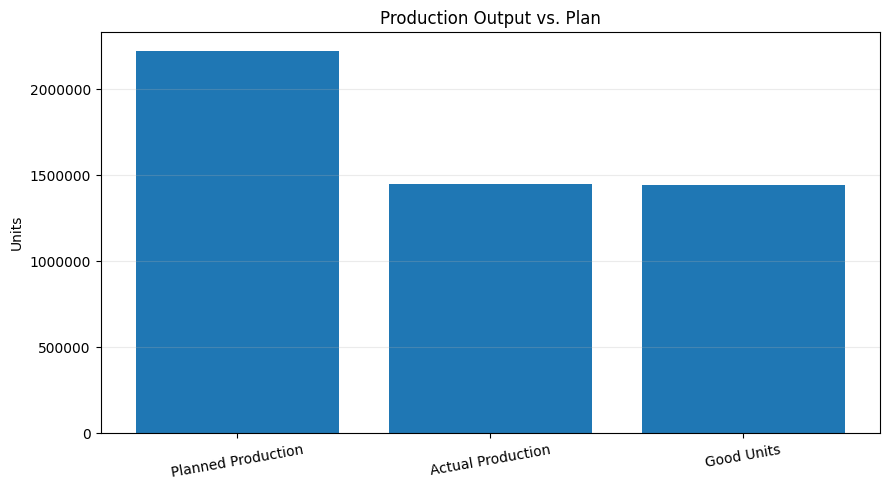

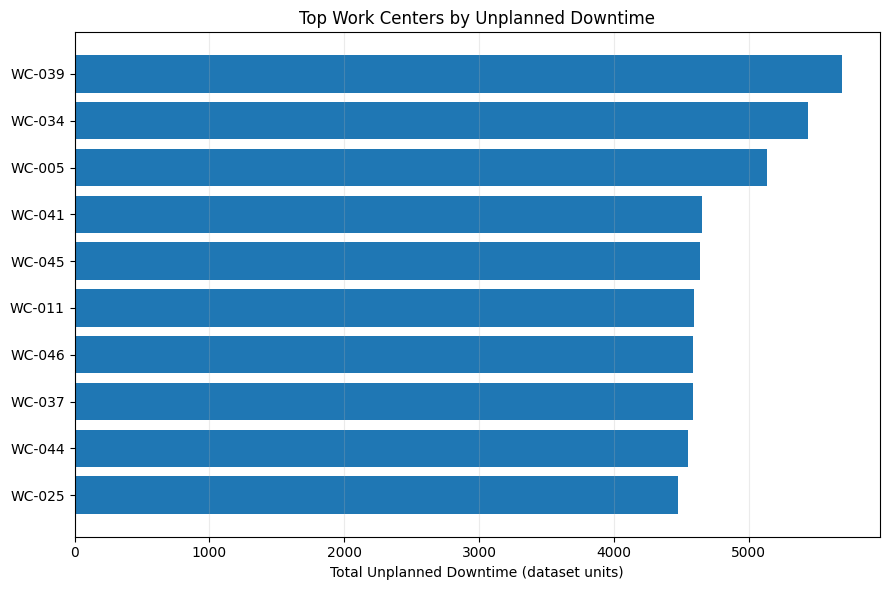

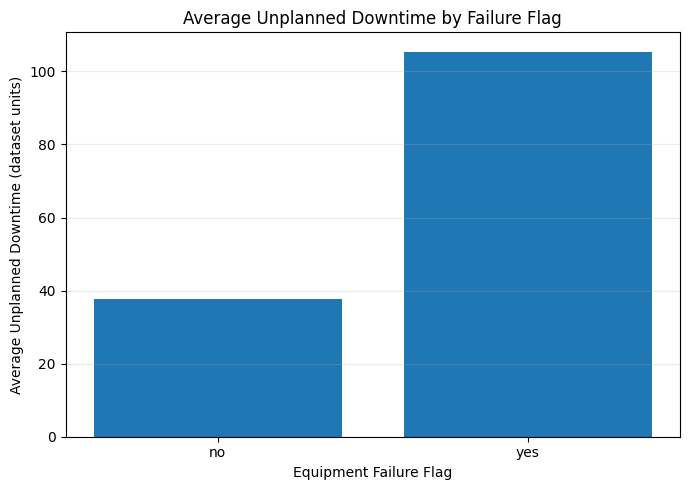

Saved visualization files:
['production_output_vs_plan.png', 'equipment_failure_downtime.png', 'work_center_downtime.png']


In [104]:

import os
import matplotlib.pyplot as plt

visualizations_dir = "Visualizations"
os.makedirs(visualizations_dir, exist_ok=True)

# 1. Production output vs. plan
p = production_results.iloc[0]
planned = int(p["planned_units"])
actual = int(p["actual_units"])
good = int(p["good_units"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    ["Planned Production", "Actual Production", "Good Units"],
    [planned, actual, good]
)
ax.set_title("Production Output vs. Plan")
ax.set_ylabel("Units")
ax.ticklabel_format(axis="y", style="plain")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=10)
plt.tight_layout()
fig.savefig(
    os.path.join(visualizations_dir, "production_output_vs_plan.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 2. Work center downtime
d = downtime_results.copy()
downtime_plot = d.sort_values(
    "total_unplanned_downtime", ascending=True
).tail(10)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    downtime_plot["work_center_id"].astype(str),
    downtime_plot["total_unplanned_downtime"]
)
ax.set_title("Top Work Centers by Unplanned Downtime")
ax.set_xlabel("Total Unplanned Downtime (dataset units)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
fig.savefig(
    os.path.join(visualizations_dir, "work_center_downtime.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 3. Equipment failure comparison
f = failure_results.copy()

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(
    f.iloc[:, 0].astype(str),
    f["avg_unplanned_downtime"]
)
ax.set_title("Average Unplanned Downtime by Failure Flag")
ax.set_xlabel("Equipment Failure Flag")
ax.set_ylabel("Average Unplanned Downtime (dataset units)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(
    os.path.join(visualizations_dir, "equipment_failure_downtime.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved visualization files:")
print(os.listdir(visualizations_dir))


In [105]:

import os
import shutil
import zipfile

project_name = "aerospace-automated-cell-oee-analytics"
os.makedirs(project_name, exist_ok=True)

# Create the project folders
folders = [
    "Results", "Visualizations", "Documentation",
    "SQL", "Python", "Dashboard", "Data"
]

for folder in folders:
    os.makedirs(os.path.join(project_name, folder), exist_ok=True)

# Save all seven validated analysis outputs
results = {
    "production_performance_results.csv": production_results,
    "work_center_downtime_results.csv": downtime_results,
    "equipment_failure_analysis.csv": failure_results,
    "bottleneck_station_analysis.csv": bottleneck_results,
    "maintenance_condition_analysis.csv": maintenance_results,
    "production_quality_analysis.csv": quality_results,
    "downtime_quality_cost_analysis.csv": cost_results,
}

for filename, data in results.items():
    data.to_csv(
        os.path.join(project_name, "Results", filename),
        index=False
    )

# Copy the three saved charts into the project
chart_files = [
    "production_output_vs_plan.png",
    "work_center_downtime.png",
    "equipment_failure_downtime.png",
]

for filename in chart_files:
    source = os.path.join("Visualizations", filename)

    if not os.path.exists(source):
        raise FileNotFoundError(
            f"Missing chart: {source}. "
            "Check where your charts were saved."
        )

    shutil.copy2(
        source,
        os.path.join(project_name, "Visualizations", filename)
    )

# Create a starter README
readme = """# Aerospace Automated Manufacturing Cell
## OEE, Production & Automation Analytics

### Overview
A synthetic manufacturing case study analyzing production
performance, equipment downtime, failures, bottlenecks,
maintenance, product quality, and cost exposure.

### Dataset
- 3,000 validated records
- Synthetic manufacturing data
- SQL, Python, pandas, and Matplotlib

### Key Findings
- Planned production: 2,219,673 units
- Actual production: 1,448,365 units
- Good units: 1,444,421
- Defective units: 3,944
- Scrap units: 393
- Production target achievement: 65.25%
- Good-unit rate: 99.73%
- WC-039 ranked highest in the analyzed work centers
  for unplanned downtime and combined cost exposure.

### Project Contents
- Results: seven CSV analysis outputs
- Visualizations: three PNG charts
- SQL, Python, Dashboard, Data, and Documentation:
  folders for future project files

### Limitations
This is a synthetic case study. It does not represent
actual Airbus, HII, or other company performance.
Cost figures are illustrative, and associations do not
prove causation.
"""

with open(
    os.path.join(project_name, "README.md"),
    "w",
    encoding="utf-8"
) as file:
    file.write(readme)

# Create a ZIP archive for download
zip_path = project_name + ".zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for current_root, _, filenames in os.walk(project_name):
        for filename in filenames:
            full_path = os.path.join(current_root, filename)
            archive.write(
                full_path,
                arcname=os.path.relpath(full_path, ".")
            )

print("Project package created:", zip_path)
print("CSV analysis files:", len(results))
print("Chart files:", len(chart_files))
print("README created: Yes")

# Download the ZIP to your computer
from google.colab import files
files.download(zip_path)


Project package created: aerospace-automated-cell-oee-analytics.zip
CSV analysis files: 7
Chart files: 3
README created: Yes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [106]:
df_full.columns.tolist()

['line_id',
 'plant_id',
 'work_center_id',
 'shift_id',
 'shift_date',
 'shift_number',
 'shift_duration_minutes',
 'product_id',
 'product_family',
 'production_order_id',
 'line_type',
 'automation_level',
 'number_of_stations',
 'line_configuration',
 'plant_location',
 'industry_sector',
 'takt_time_seconds',
 'designed_cycle_time_seconds',
 'actual_cycle_time_avg_seconds',
 'actual_cycle_time_std_seconds',
 'actual_cycle_time_min_seconds',
 'actual_cycle_time_max_seconds',
 'cycle_time_percentile_p50',
 'cycle_time_percentile_p95',
 'cycle_time_cov',
 'bottleneck_station_id',
 'bottleneck_cycle_time_seconds',
 'bottleneck_utilisation_pct',
 'secondary_bottleneck_station_id',
 'cycle_time_loss_seconds',
 'planned_production_quantity',
 'actual_production_quantity',
 'good_units_produced',
 'defective_units_produced',
 'scrap_units',
 'rework_units',
 'throughput_rate_actual_uph',
 'throughput_rate_design_uph',
 'throughput_rate_ratio',
 'rolled_throughput_yield_pct',
 'total_parts

In [107]:
import pandas as pd

url = "https://huggingface.co/datasets/xpertsystems/mfg005-sample/resolve/main/mfg005_synthetic_line_performance.csv"

df_full = pd.read_csv(url)

print("Dataset shape:", df_full.shape)
print("\nColumn names:")
print(df_full.columns.tolist())

Dataset shape: (3000, 118)

Column names:
['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date', 'shift_number', 'shift_duration_minutes', 'product_id', 'product_family', 'production_order_id', 'line_type', 'automation_level', 'number_of_stations', 'line_configuration', 'plant_location', 'industry_sector', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_min_seconds', 'actual_cycle_time_max_seconds', 'cycle_time_percentile_p50', 'cycle_time_percentile_p95', 'cycle_time_cov', 'bottleneck_station_id', 'bottleneck_cycle_time_seconds', 'bottleneck_utilisation_pct', 'secondary_bottleneck_station_id', 'cycle_time_loss_seconds', 'planned_production_quantity', 'actual_production_quantity', 'good_units_produced', 'defective_units_produced', 'scrap_units', 'rework_units', 'throughput_rate_actual_uph', 'throughput_rate_design_uph', 'throughput_rate_ratio', 'rolled_throughput_yield_pct', 'total_par

In [108]:

import pandas as pd
import sqlite3

# Load the full synthetic manufacturing dataset
url = "https://huggingface.co/datasets/xpertsystems/mfg005-sample/resolve/main/mfg005_synthetic_line_performance.csv"

df_full = pd.read_csv(url)

# Create an in-memory SQLite database
conn = sqlite3.connect(":memory:")

# Load manufacturing records into SQL
df_full.to_sql(
    "production_data",
    conn,
    if_exists="replace",
    index=False
)

# Verify database contents
result = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_records,
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    SUM(good_units_produced) AS good_units
FROM production_data;
""", conn)

print(result.to_string(index=False))


 total_records  planned_units  actual_units  good_units
          3000        2219673       1448365     1444421


In [109]:

# Test production analysis SQL

query = """
SELECT
    work_center_id,
    SUM(planned_production_quantity) AS planned_units,
    SUM(actual_production_quantity) AS actual_units,
    ROUND(
        100.0 * SUM(actual_production_quantity)
        / NULLIF(SUM(planned_production_quantity), 0),
        2
    ) AS target_achievement_pct
FROM production_data
GROUP BY work_center_id
ORDER BY target_achievement_pct ASC
LIMIT 10;
"""

production_test = pd.read_sql_query(query, conn)

print("10 work centers with lowest production achievement:")
print(production_test.to_string(index=False))


10 work centers with lowest production achievement:
work_center_id  planned_units  actual_units  target_achievement_pct
        WC-022          33939         19677                   57.98
        WC-047          43680         26807                   61.37
        WC-026          57845         35580                   61.51
        WC-028          44307         27435                   61.92
        WC-041          48924         30393                   62.12
        WC-029          37445         23353                   62.37
        WC-002          38149         23872                   62.58
        WC-027          44536         28020                   62.92
        WC-032          45179         28432                   62.93
        WC-015          53013         33438                   63.08


In [110]:

query = """
SELECT
    equipment_failure_flag,
    COUNT(*) AS record_count,
    ROUND(AVG(downtime_unplanned_minutes), 2)
        AS avg_unplanned_downtime,
    ROUND(AVG(mttr_minutes), 2) AS avg_mttr,
    ROUND(AVG(mtbf_minutes), 2) AS avg_mtbf
FROM production_data
GROUP BY equipment_failure_flag;
"""

downtime_test = pd.read_sql_query(query, conn)

print("Equipment failure and downtime analysis:")
print(downtime_test.to_string(index=False))


Equipment failure and downtime analysis:
equipment_failure_flag  record_count  avg_unplanned_downtime  avg_mttr  avg_mtbf
                    no          1846                   37.56     12.30    235.57
                   yes          1154                  105.41     25.38    139.53


In [111]:

query = """
SELECT
    COUNT(*) AS total_records,
    SUM(
        CASE
            WHEN LOWER(TRIM(equipment_failure_flag)) = 'yes'
            THEN 1 ELSE 0
        END
    ) AS failure_records,
    ROUND(AVG(mtbf_minutes), 2) AS avg_mtbf,
    ROUND(AVG(mttr_minutes), 2) AS avg_mttr,
    ROUND(AVG(equipment_condition_score), 2)
        AS avg_condition_score
FROM production_data;
"""

reliability_test = pd.read_sql_query(query, conn)
print(reliability_test.to_string(index=False))


 total_records  failure_records  avg_mtbf  avg_mttr  avg_condition_score
          3000             1154    198.63     17.33                 6.01


In [112]:

query = """
SELECT
    work_center_id,
    COUNT(*) AS production_records,
    ROUND(SUM(cycle_time_loss_seconds), 2)
        AS total_cycle_time_loss_seconds,
    ROUND(AVG(bottleneck_utilisation_pct), 2)
        AS avg_bottleneck_utilisation_pct,
    ROUND(AVG(wip_queue_avg_units), 2)
        AS avg_wip_queue_units
FROM production_data
GROUP BY work_center_id
ORDER BY total_cycle_time_loss_seconds DESC
LIMIT 10;
"""

bottleneck_test = pd.read_sql_query(query, conn)

print("Top 10 work centers by cycle-time loss:")
print(bottleneck_test.to_string(index=False))


Top 10 work centers by cycle-time loss:
work_center_id  production_records  total_cycle_time_loss_seconds  avg_bottleneck_utilisation_pct  avg_wip_queue_units
        WC-034                  81                        8170.65                           94.84                 1.28
        WC-046                  71                        8011.05                           95.09                 1.19
        WC-041                  64                        7308.53                           95.55                 1.60
        WC-039                  77                        7218.04                           95.16                 1.33
        WC-020                  65                        7159.13                           95.21                 1.32
        WC-037                  66                        7016.59                           95.35                 1.41
        WC-019                  64                        6736.38                           95.03                 1.74
        

In [113]:

query = """
SELECT
    work_center_id,
    SUM(defective_units_produced) AS defective_units,
    SUM(scrap_units) AS scrap_units,
    SUM(rework_units) AS rework_units,
    ROUND(SUM(total_downtime_cost_usd), 2)
        AS downtime_cost_usd,
    ROUND(SUM(cost_of_poor_quality_usd), 2)
        AS poor_quality_cost_usd,
    ROUND(
        SUM(total_downtime_cost_usd)
        + SUM(cost_of_poor_quality_usd),
        2
    ) AS combined_cost_usd
FROM production_data
GROUP BY work_center_id
ORDER BY combined_cost_usd DESC
LIMIT 10;
"""

quality_cost_test = pd.read_sql_query(query, conn)

print("Top 10 work centers by combined cost:")
print(quality_cost_test.to_string(index=False))


Top 10 work centers by combined cost:
work_center_id  defective_units  scrap_units  rework_units  downtime_cost_usd  poor_quality_cost_usd  combined_cost_usd
        WC-039              121           19           102          802824.16              161571.50          964395.66
        WC-034               95            5            90          743613.85              149608.59          893222.44
        WC-005               84            7            77          730182.02              146670.31          876852.33
        WC-044               84            4            80          709219.64              142652.79          851872.43
        WC-045               76            4            72          707102.00              141947.76          849049.76
        WC-025               75            2            73          704621.00              141624.96          846245.96
        WC-002               69            3            66          680741.00              136819.02          817560.02
  

In [114]:

import os

os.makedirs("Results", exist_ok=True)

production_test.to_csv(
    "Results/production_achievement_verified.csv",
    index=False
)

downtime_test.to_csv(
    "Results/equipment_failure_downtime_verified.csv",
    index=False
)

reliability_test.to_csv(
    "Results/equipment_reliability_verified.csv",
    index=False
)

bottleneck_test.to_csv(
    "Results/bottleneck_analysis_verified.csv",
    index=False
)

quality_cost_test.to_csv(
    "Results/quality_cost_analysis_verified.csv",
    index=False
)

print("All five verified SQL result files saved.")
print(os.listdir("Results"))


All five verified SQL result files saved.
['bottleneck_analysis_verified.csv', 'production_achievement_verified.csv', 'quality_cost_analysis_verified.csv', 'equipment_reliability_verified.csv', 'equipment_failure_downtime_verified.csv']


In [115]:

import shutil
from google.colab import files

shutil.make_archive(
    "verified_sql_results",
    "zip",
    "Results"
)

files.download("verified_sql_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [116]:

import requests
import sqlite3
import pandas as pd

repo = "https://raw.githubusercontent.com/hwant2/aerospace-automated-cell-oee-analytics/main/SQL/"

scripts = [
    "production_analysis.sql",
    "downtime_analysis.sql",
    "reliability_analysis.sql",
    "bottleneck_analysis.sql",
    "quality_cost_analysis.sql"
]

# Rebuild the database if the runtime was restarted
if "conn" not in globals():
    url = "https://huggingface.co/datasets/xpertsystems/mfg005-sample/resolve/main/mfg005_synthetic_line_performance.csv"
    df_full = pd.read_csv(url)
    conn = sqlite3.connect(":memory:")
    df_full.to_sql("production_data", conn, if_exists="replace", index=False)

for script in scripts:
    print(f"\nTesting {script}")
    response = requests.get(repo + script, timeout=30)
    response.raise_for_status()

    sql_text = response.text
    statements = [
        s.strip()
        for s in sql_text.split(";")
        if s.strip()
    ]

    for i, statement in enumerate(statements, 1):
        try:
            result = pd.read_sql_query(statement, conn)
            print(f"  Query {i}: PASS ({len(result)} rows)")
        except Exception as e:
            print(f"  Query {i}: FAIL - {e}")



Testing production_analysis.sql
  Query 1: PASS (1 rows)
  Query 2: PASS (49 rows)
  Query 3: PASS (49 rows)
  Query 4: PASS (3 rows)

Testing downtime_analysis.sql
  Query 1: PASS (1 rows)
  Query 2: PASS (49 rows)
  Query 3: PASS (2 rows)
  Query 4: PASS (1 rows)
  Query 5: PASS (20 rows)

Testing reliability_analysis.sql
  Query 1: PASS (1 rows)
  Query 2: PASS (49 rows)
  Query 3: PASS (8 rows)
  Query 4: PASS (4 rows)

Testing bottleneck_analysis.sql
  Query 1: PASS (15 rows)
  Query 2: PASS (20 rows)
  Query 3: PASS (49 rows)
  Query 4: PASS (5 rows)
  Query 5: PASS (15 rows)

Testing quality_cost_analysis.sql
  Query 1: PASS (1 rows)
  Query 2: PASS (49 rows)
  Query 3: PASS (1 rows)
  Query 4: PASS (15 rows)
  Query 5: PASS (3 rows)
  Query 6: PASS (5 rows)
